# Task 3 (Level 2 — Intermediate): Logistic Regression for Binary Customer Churn

Preserves the official `churn-bigml-80.csv` ($n=2,666$) and `churn-bigml-20.csv` ($n=667$) partitions, removes deterministic billing collinearity, tunes `C` and `class_weight` via 5-fold Stratified CV, calibrates classification probability thresholds strictly via out-of-fold (`cross_val_predict`) training probabilities, and computes 1,000-resample stratified bootstrap 95% confidence intervals on odds ratios.

In [1]:
import json
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
m3 = json.loads((ROOT / 'results/metrics/task3_logistic_regression_metrics.json').read_text())
odds_df = pd.read_csv(ROOT / 'results/tables/task3_logreg_odds_ratios_bootstrap.csv')
print('Best CV Hyperparameters:', m3['best_hyperparameters'])
for label, key in [('Dummy Baseline', 'dummy_baseline_test'), ('Tuned LogReg (Thr=0.50)', 'tuned_logreg_test_default_050'), ('Tuned LogReg (OOF Thr=0.64)', 'tuned_logreg_test_oof_optimal')]:
    ev = m3[key]
    print(f"{label:28s} | Acc={ev['accuracy']:.4f} | Prec={ev['precision']:.4f} | Rec={ev['recall']:.4f} | F1={ev['f1']:.4f} | AUC={ev['roc_auc']:.4f} | PR-AUC={ev['pr_auc']:.4f}")

Best CV Hyperparameters: {'C': 0.1, 'class_weight': 'balanced', 'cv_roc_auc_mean': 0.811239, 'oof_selected_threshold': 0.64, 'oof_f1_at_selected_threshold': 0.49711, 'oof_cost_optimal_threshold_fn5_fp1': 0.54}
Dummy Baseline               | Acc=0.8576 | Prec=0.0000 | Rec=0.0000 | F1=0.0000 | AUC=0.5000 | PR-AUC=0.1424
Tuned LogReg (Thr=0.50)      | Acc=0.7661 | Prec=0.3512 | Rec=0.7579 | F1=0.4800 | AUC=0.8274 | PR-AUC=0.4271
Tuned LogReg (OOF Thr=0.64)  | Acc=0.8246 | Prec=0.4113 | Rec=0.5368 | F1=0.4658 | AUC=0.8274 | PR-AUC=0.4271


## 3.1 Statistical Interpretation of Coefficients & Odds Ratios

In [2]:
print('Top Positive Churn Associations (Odds Ratio > 1):')
display(odds_df[['clean_feature', 'scale_basis', 'coef', 'odds_ratio', 'or_ci_low', 'or_ci_high']].head(8))
print('Top Retention Associations (Odds Ratio < 1):')
display(odds_df[['clean_feature', 'scale_basis', 'coef', 'odds_ratio', 'or_ci_low', 'or_ci_high']].tail(6))

Top Positive Churn Associations (Odds Ratio > 1):


,clean_feature,scale_basis,coef,odds_ratio,or_ci_low,or_ci_high
0,International Plan = Yes,Binary Indicator (1 vs 0),1.985206,7.280550,5.512301,9.791843
1,Customer service calls,Per +1 Train SD,0.718116,2.050566,1.847083,2.358430
2,Total day minutes,Per +1 Train SD,0.632913,1.883089,1.675866,2.176843
3,State = TX,Binary Indicator (1 vs 0),0.568468,1.765560,1.207908,2.556102
4,State = SC,Binary Indicator (1 vs 0),0.544022,1.722923,1.069828,2.732932
5,State = MS,Binary Indicator (1 vs 0),0.510406,1.665967,1.025828,2.651401
6,State = MT,Binary Indicator (1 vs 0),0.471151,1.601837,0.986288,2.449146
7,State = NJ,Binary Indicator (1 vs 0),0.387793,1.473724,0.974197,2.208465


Top Retention Associations (Odds Ratio < 1):


,clean_feature,scale_basis,coef,odds_ratio,or_ci_low,or_ci_high
61,State = AL,Binary Indicator (1 vs 0),-0.317721,0.727806,0.518385,0.987074
62,State = IL,Binary Indicator (1 vs 0),-0.350220,0.704533,0.508460,1.017475
63,State = HI,Binary Indicator (1 vs 0),-0.484819,0.615809,0.481751,0.811559
64,State = VA,Binary Indicator (1 vs 0),-0.503873,0.604186,0.420033,0.876873
65,State = RI,Binary Indicator (1 vs 0),-0.570996,0.564962,0.460824,0.700526
66,Voice Mail Plan = Yes,Binary Indicator (1 vs 0),-0.692180,0.500484,0.344667,0.728785


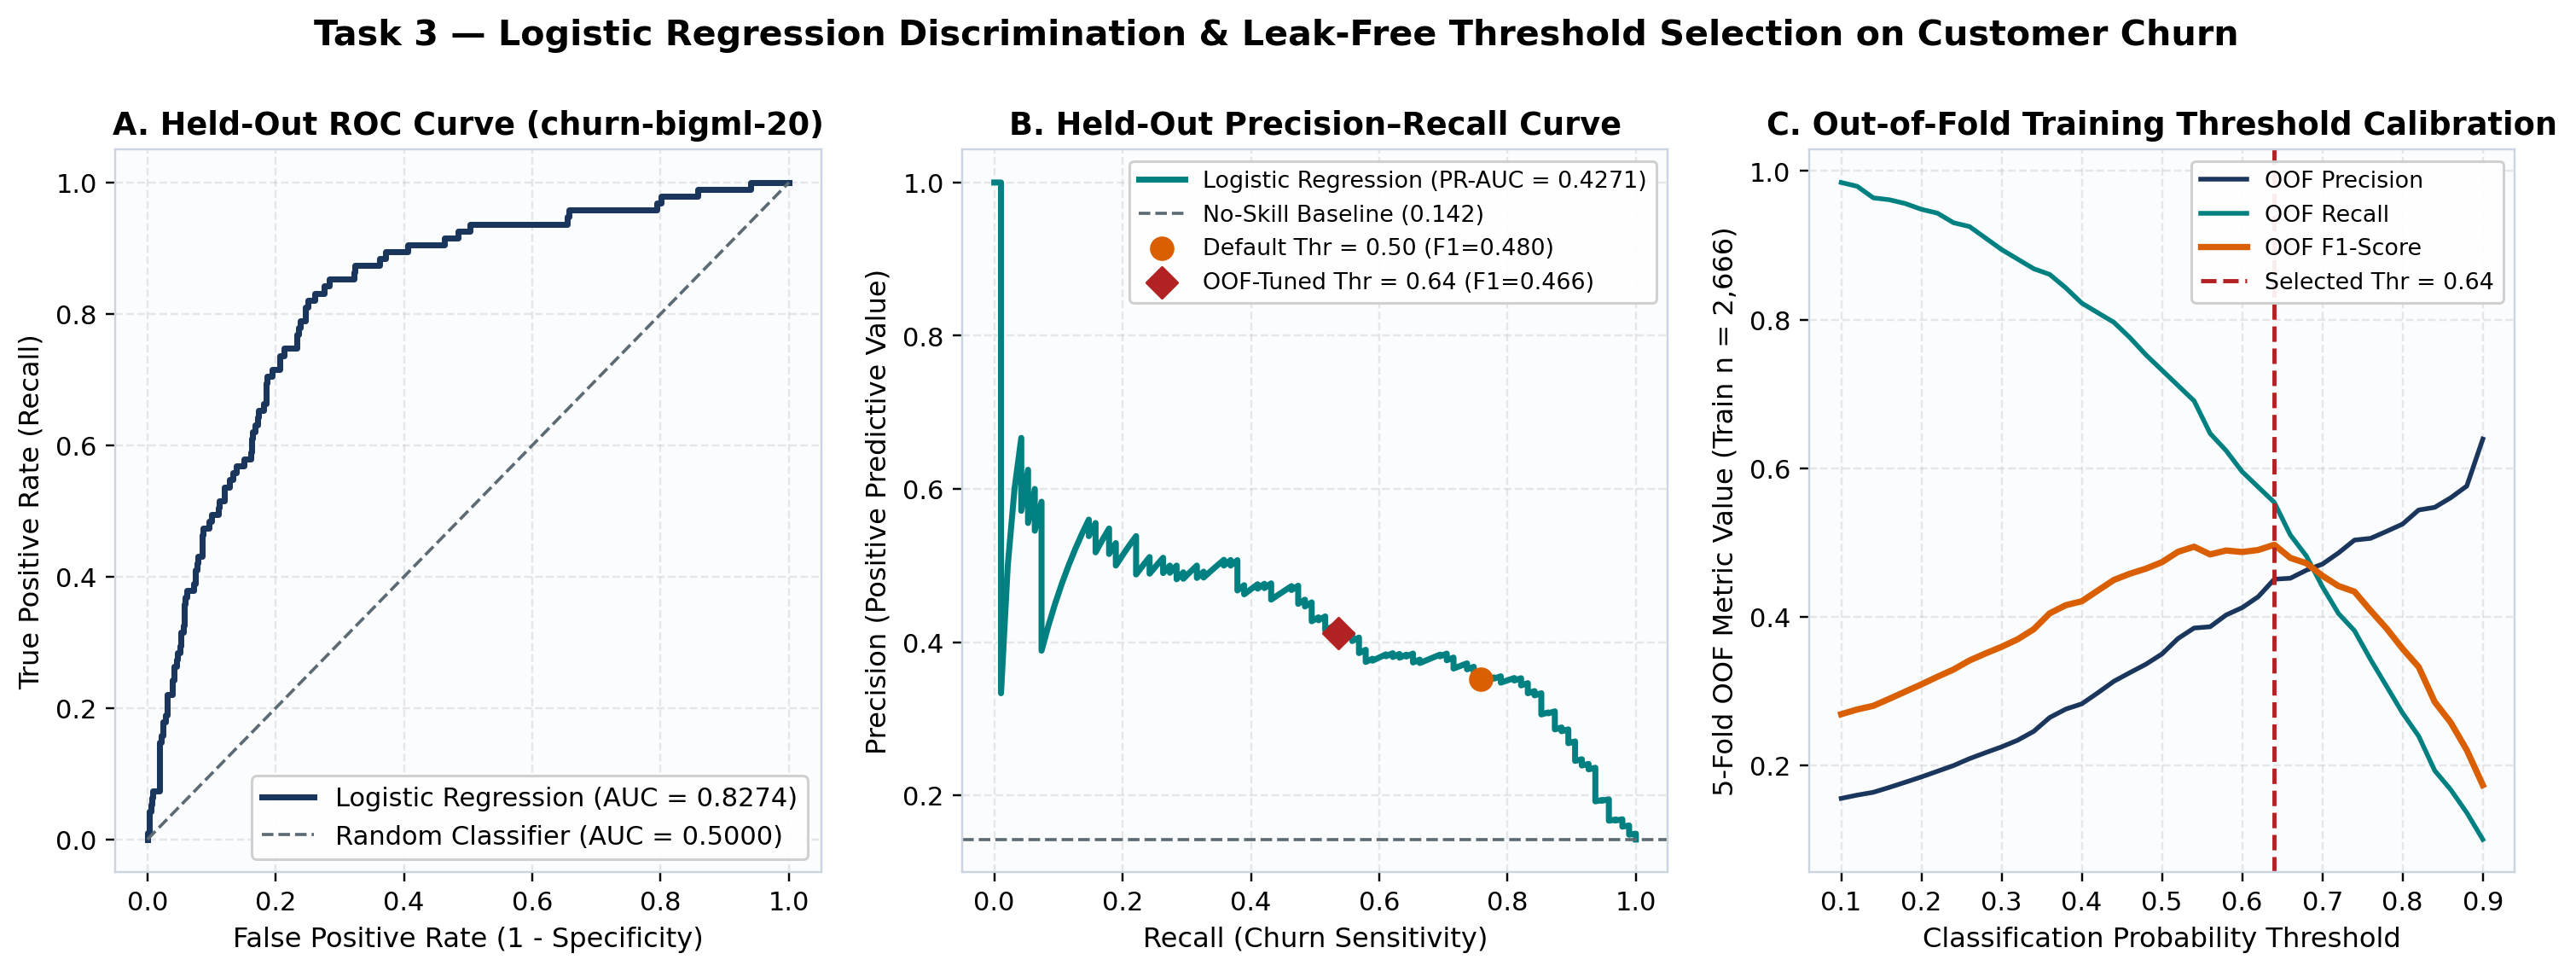

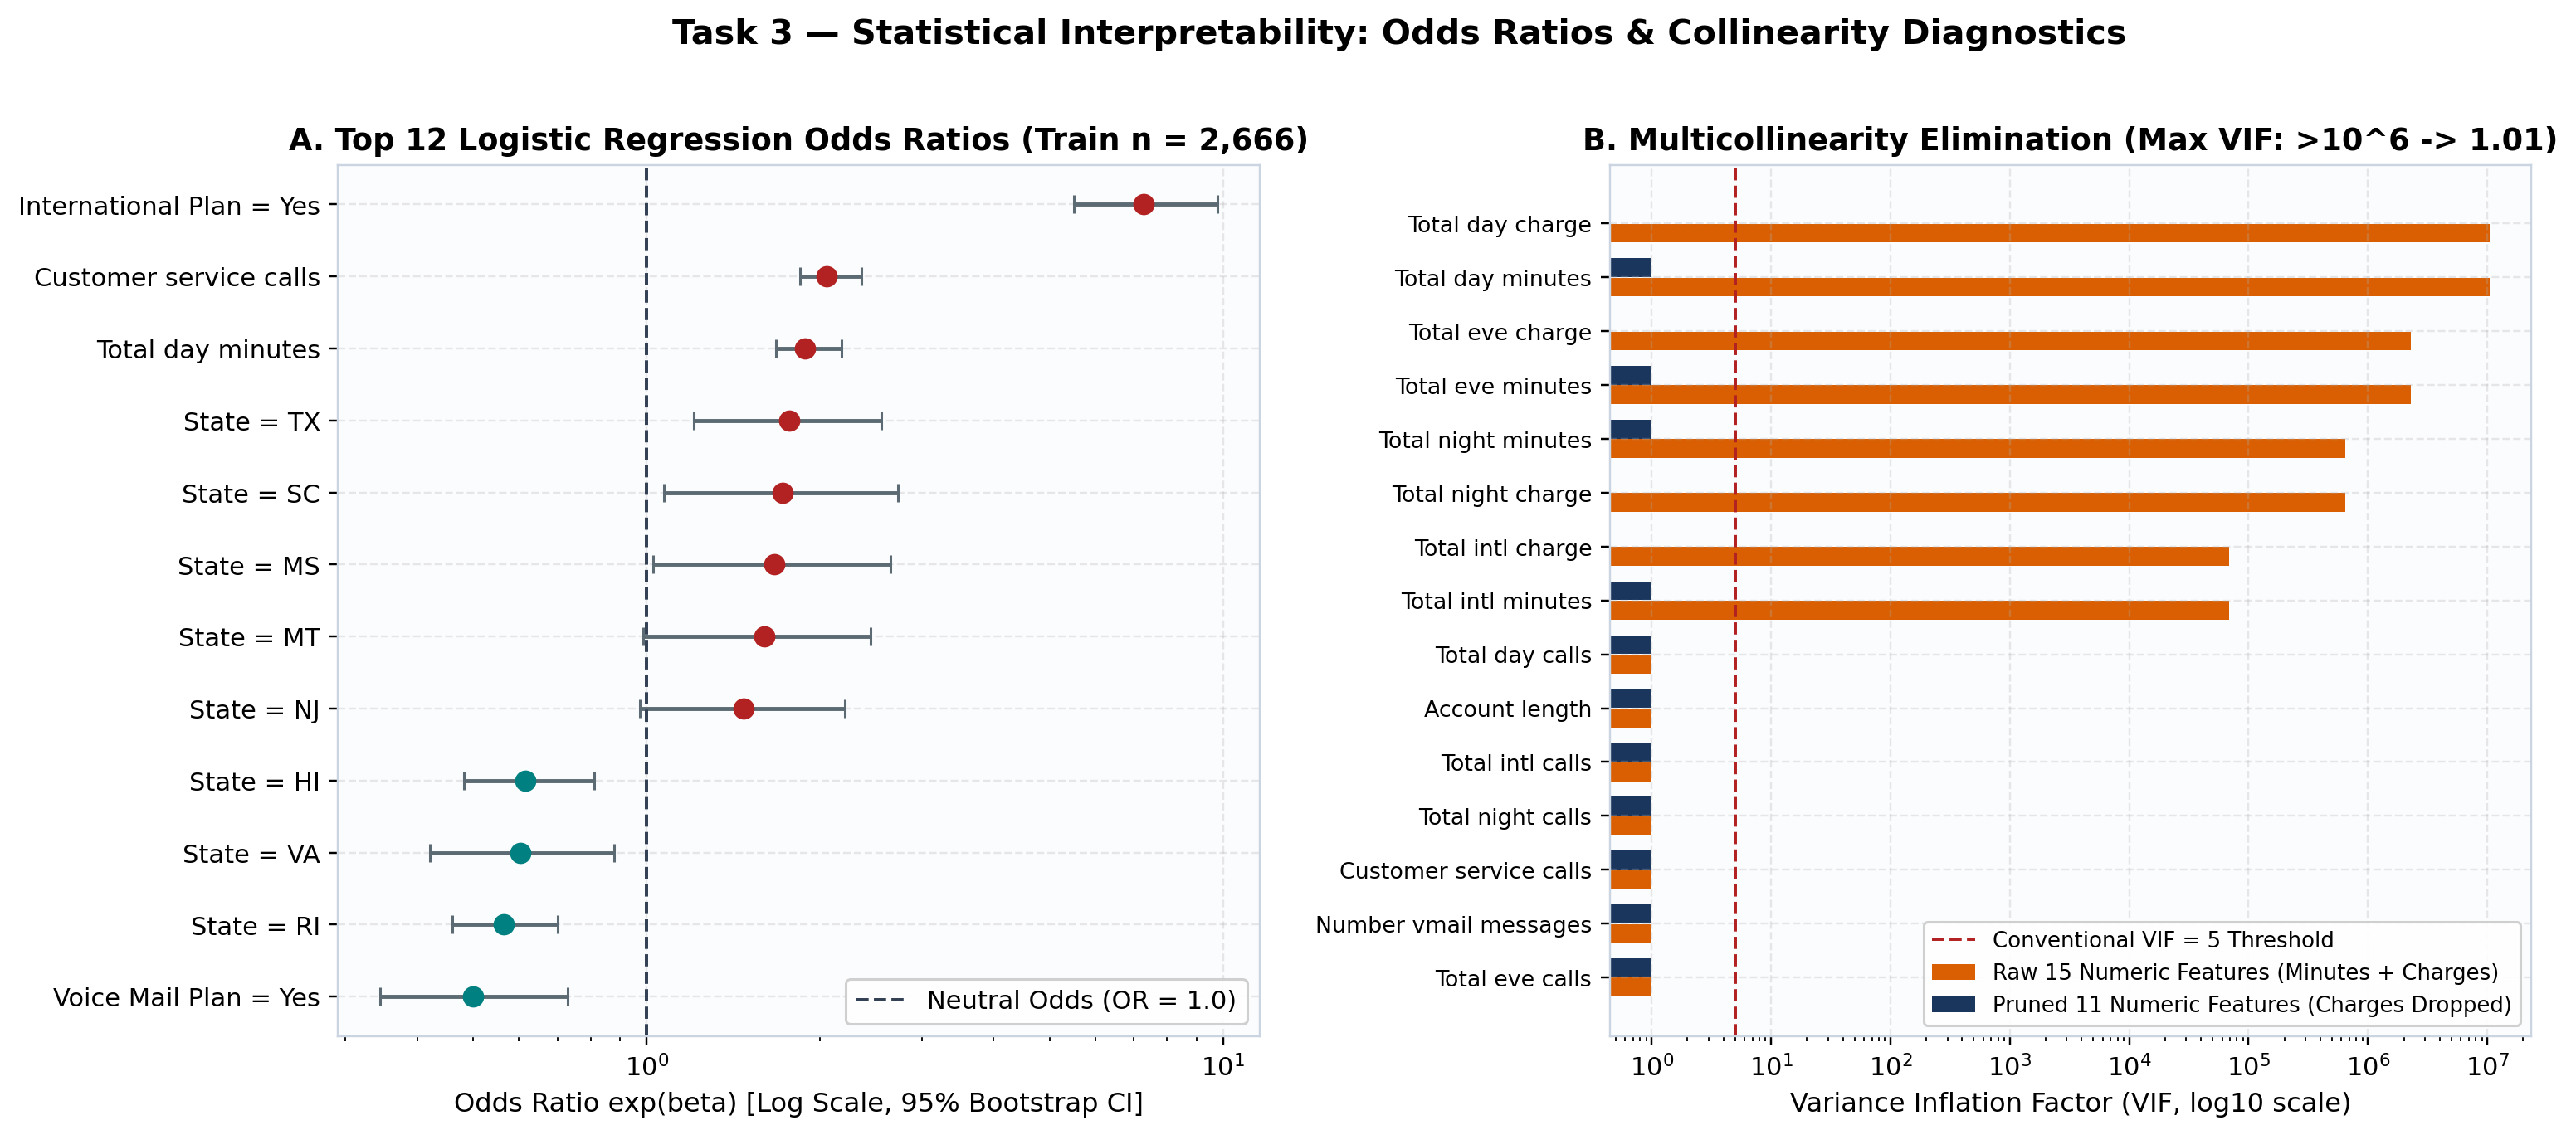

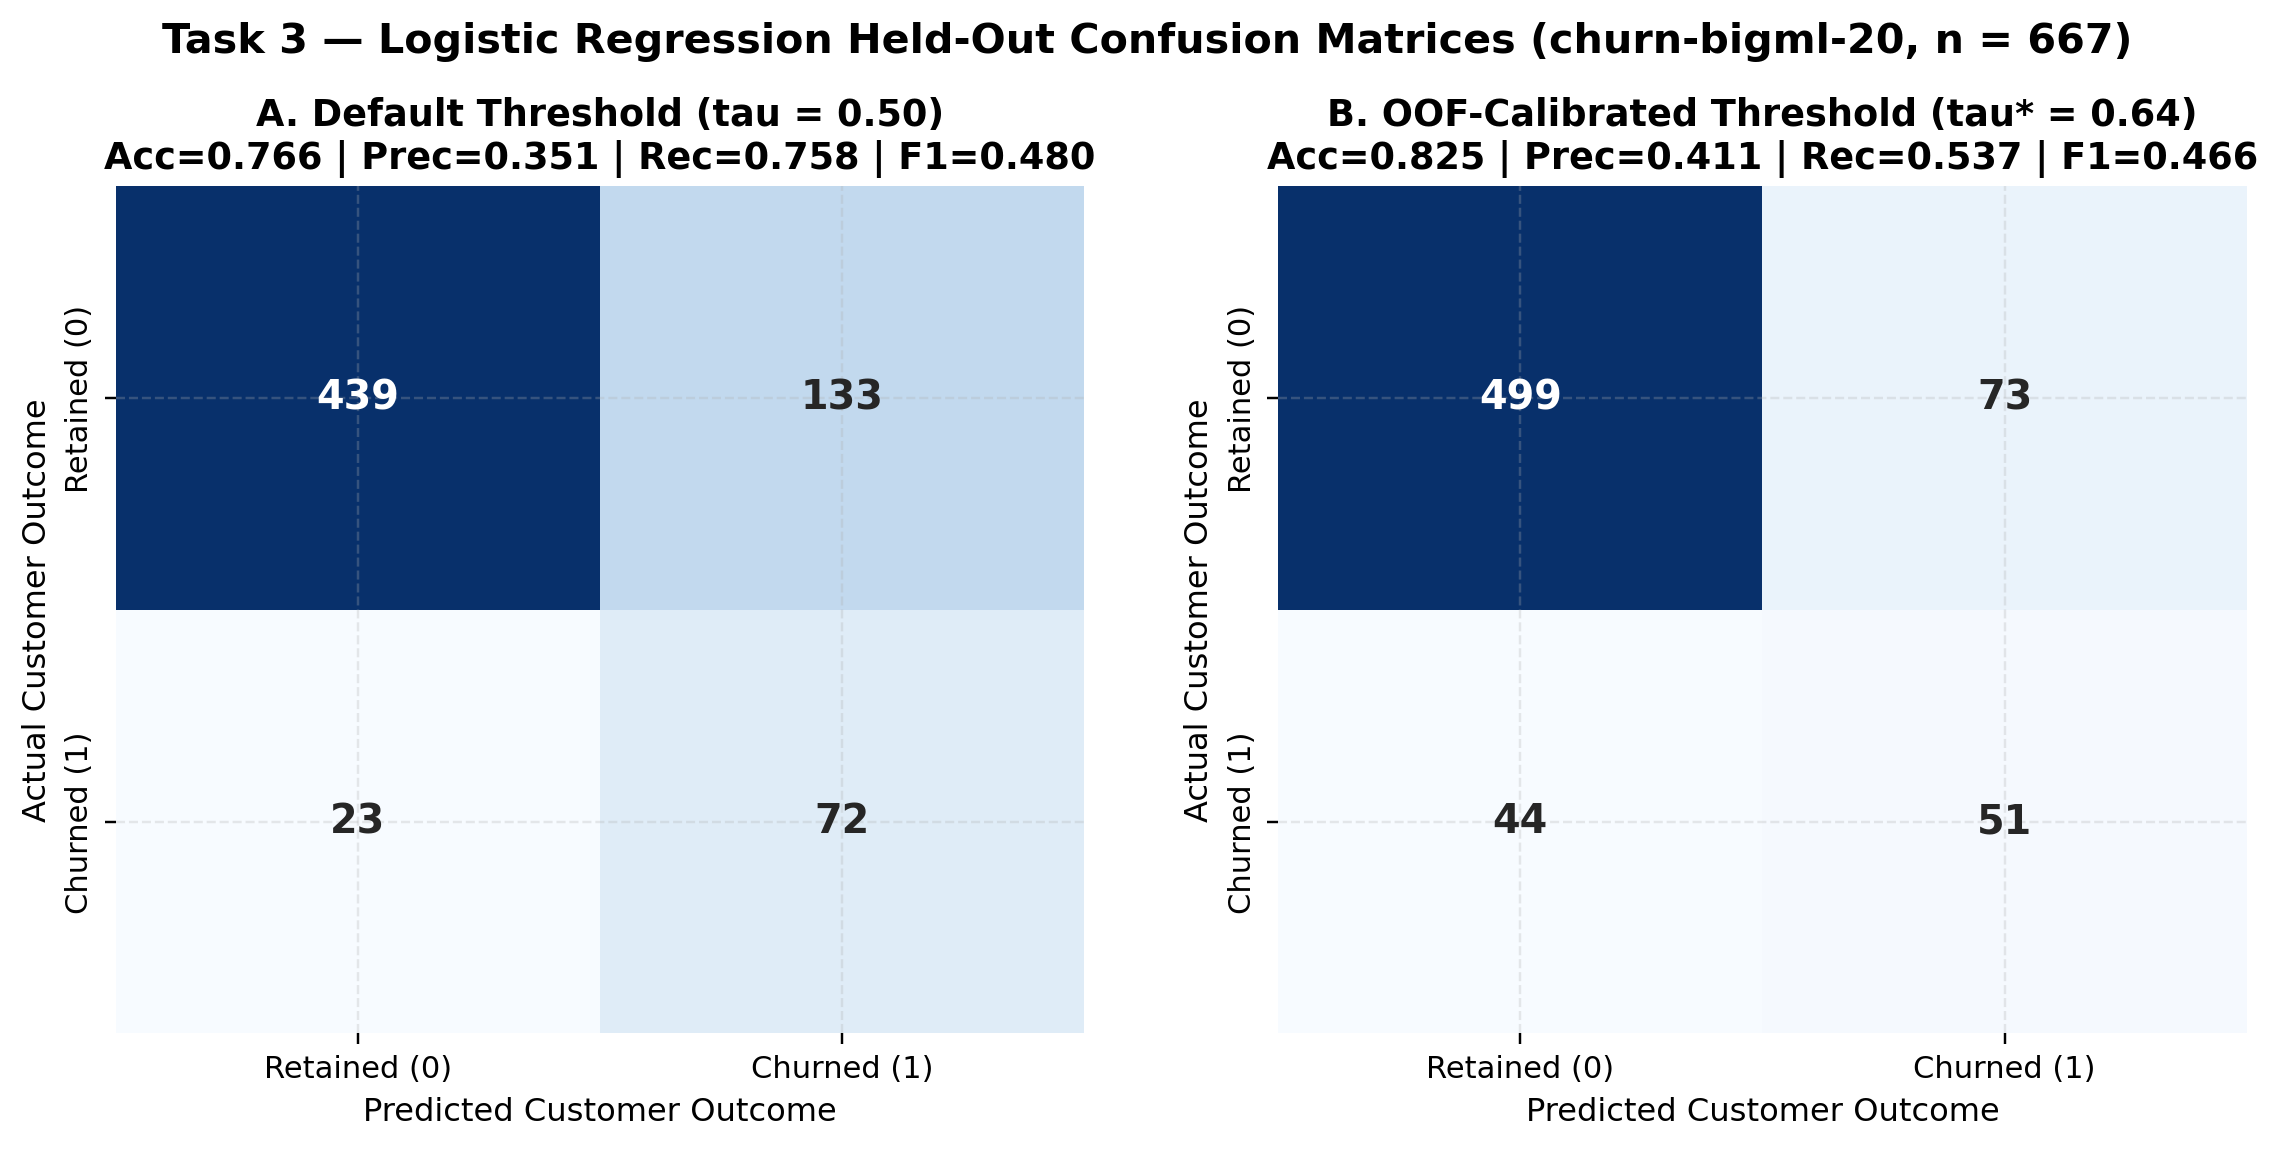

In [3]:
display(Image(filename=str(ROOT / 'results/figures/fig05_logreg_roc_pr_and_threshold_sweep.png')))
display(Image(filename=str(ROOT / 'results/figures/fig06_logreg_odds_ratios_and_vif.png')))
display(Image(filename=str(ROOT / 'results/figures/fig07_logreg_confusion_matrices.png')))